Library

In [105]:
import pandas as pd
import tensorflow as tf
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Input
import matplotlib.pyplot as plt
import os
import random
import numpy as np

random.seed(42)
np.random.seed(42)
tf.random.set_seed(42)

Sequential API single regression

In [106]:
from sklearn.datasets import fetch_california_housing

data = fetch_california_housing()
df = pd.DataFrame(data.data, columns=data.feature_names)
df['target'] = data.target
df

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,target
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422
...,...,...,...,...,...,...,...,...,...
20635,1.5603,25.0,5.045455,1.133333,845.0,2.560606,39.48,-121.09,0.781
20636,2.5568,18.0,6.114035,1.315789,356.0,3.122807,39.49,-121.21,0.771
20637,1.7000,17.0,5.205543,1.120092,1007.0,2.325635,39.43,-121.22,0.923
20638,1.8672,18.0,5.329513,1.171920,741.0,2.123209,39.43,-121.32,0.847


In [107]:
train_df, test_df = train_test_split(df, test_size=0.2, random_state=42)

scaler = StandardScaler()
X_train = scaler.fit_transform(train_df[data.feature_names])
X_test = scaler.transform(test_df[data.feature_names])
y_train = train_df['target'].values
y_test = test_df['target'].values

batch_size = 32
train_ds = tf.data.Dataset.from_tensor_slices((X_train, y_train)).shuffle(len(X_train)).batch(batch_size)
test_ds = tf.data.Dataset.from_tensor_slices((X_test, y_test)).batch(batch_size)

model = Sequential([
    Input(shape=(X_train.shape[1],)),
    Dense(64, activation='relu'),
    Dense(32, activation='relu'),
    Dense(1)
])
model.compile(optimizer='adam', loss='mse', metrics=['mae'])

model.fit(train_ds, epochs=20)

loss, mae = model.evaluate(test_ds)

Epoch 1/20
516/516 ━━━━━━━━━━━━━━━━━━━━ 1s 299us/step - loss: 1.7923 - mae: 0.9353
Epoch 2/20
516/516 ━━━━━━━━━━━━━━━━━━━━ 0s 273us/step - loss: 0.3997 - mae: 0.4533
Epoch 3/20
516/516 ━━━━━━━━━━━━━━━━━━━━ 0s 274us/step - loss: 0.3559 - mae: 0.4252
Epoch 4/20
516/516 ━━━━━━━━━━━━━━━━━━━━ 0s 273us/step - loss: 0.3560 - mae: 0.4195
Epoch 5/20
516/516 ━━━━━━━━━━━━━━━━━━━━ 0s 272us/step - loss: 0.3380 - mae: 0.4118
Epoch 6/20
516/516 ━━━━━━━━━━━━━━━━━━━━ 0s 279us/step - loss: 0.3427 - mae: 0.4080
Epoch 7/20
516/516 ━━━━━━━━━━━━━━━━━━━━ 0s 275us/step - loss: 0.3235 - mae: 0.4010
Epoch 8/20
516/516 ━━━━━━━━━━━━━━━━━━━━ 0s 273us/step - loss: 0.3118 - mae: 0.3880
Epoch 9/20
516/516 ━━━━━━━━━━━━━━━━━━━━ 0s 274us/step - loss: 0.3105 - mae: 0.3918
Epoch 10/20
516/516 ━━━━━━━━━━━━━━━━━━━━ 0s 273us/step - loss: 0.3102 - mae: 0.3886
Epoch 11/20
516/516 ━━━━━━━━━━━━━━━━━━━━ 0s 275us/step - loss: 0.3134 - mae: 0.3894
Epoch 12/20
516/516 ━━━━━━━━━━━━━━━━━━━━ 0s 273us/step - loss: 0.2960 - mae: 0.3810
E

In [108]:
y_pred = model.predict(test_ds).flatten()
print("Prediksi :", y_pred[:5])
print("Nilai target asli :", y_test[:5])
print(f"Test MAE : {mae:.2f}")

129/129 ━━━━━━━━━━━━━━━━━━━━ 0s 187us/step
Prediksi : [0.57789415 1.2258376  4.5128307  2.572677   3.1148496 ]
Nilai target asli : [0.477   0.458   5.00001 2.186   2.78   ]
Test MAE : 0.37


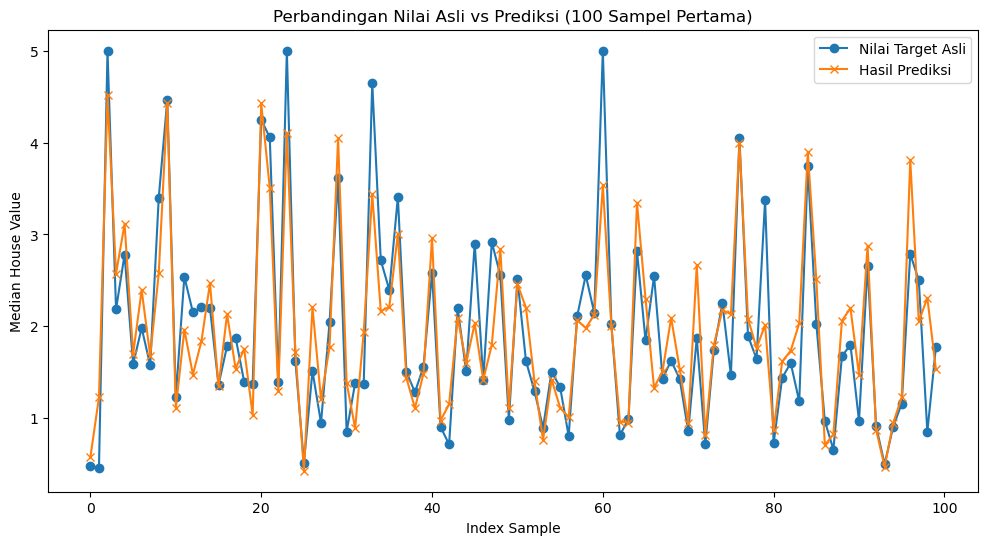

In [109]:
y_test_batches = []
for _, y in test_ds:
    y_test_batches.extend(y.numpy())
y_test_ordered = np.array(y_test_batches)

N = 100
plt.figure(figsize=(12, 6))
plt.plot(y_test_ordered[:N], label='Nilai Target Asli', marker='o')
plt.plot(y_pred[:N], label='Hasil Prediksi', marker='x')
plt.title('Perbandingan Nilai Asli vs Prediksi (100 Sampel Pertama)')
plt.xlabel('Index Sample')
plt.ylabel('Median House Value')
plt.legend()
plt.show()


Epoch 1/100
413/413 ━━━━━━━━━━━━━━━━━━━━ 1s 703us/step - loss: 1.0686 - mae: 0.7072 - val_loss: 0.3851 - val_mae: 0.4372
Epoch 2/100
413/413 ━━━━━━━━━━━━━━━━━━━━ 0s 566us/step - loss: 0.3616 - mae: 0.4241 - val_loss: 0.3634 - val_mae: 0.4242
Epoch 3/100
413/413 ━━━━━━━━━━━━━━━━━━━━ 0s 561us/step - loss: 0.3379 - mae: 0.4070 - val_loss: 0.3483 - val_mae: 0.4133
Epoch 4/100
413/413 ━━━━━━━━━━━━━━━━━━━━ 0s 558us/step - loss: 0.3232 - mae: 0.3940 - val_loss: 0.3367 - val_mae: 0.4021
Epoch 5/100
413/413 ━━━━━━━━━━━━━━━━━━━━ 0s 561us/step - loss: 0.3120 - mae: 0.3854 - val_loss: 0.3273 - val_mae: 0.3943
Epoch 6/100
413/413 ━━━━━━━━━━━━━━━━━━━━ 0s 562us/step - loss: 0.3020 - mae: 0.3777 - val_loss: 0.3217 - val_mae: 0.3885
Epoch 7/100
413/413 ━━━━━━━━━━━━━━━━━━━━ 0s 564us/step - loss: 0.2947 - mae: 0.3720 - val_loss: 0.3148 - val_mae: 0.3823
Epoch 8/100
413/413 ━━━━━━━━━━━━━━━━━━━━ 0s 560us/step - loss: 0.2889 - mae: 0.3672 - val_loss: 0.3153 - val_mae: 0.3815
Epoch 9/100
413/413 ━━━━━━━━━━━━

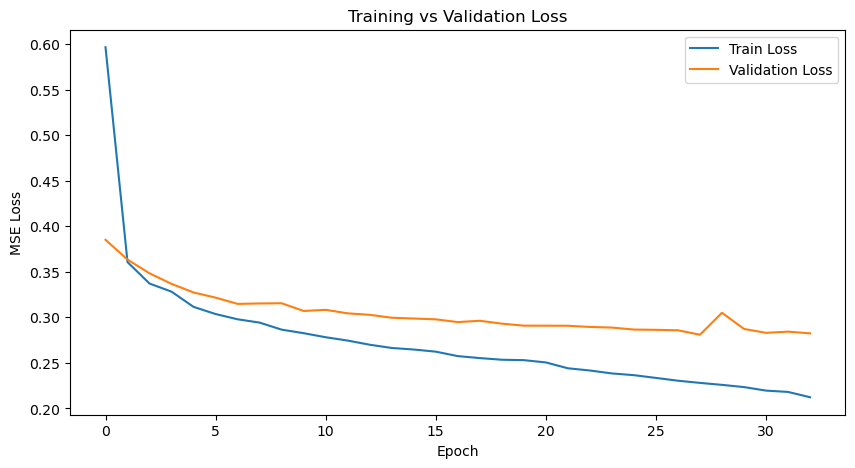

129/129 ━━━━━━━━━━━━━━━━━━━━ 0s 256us/step


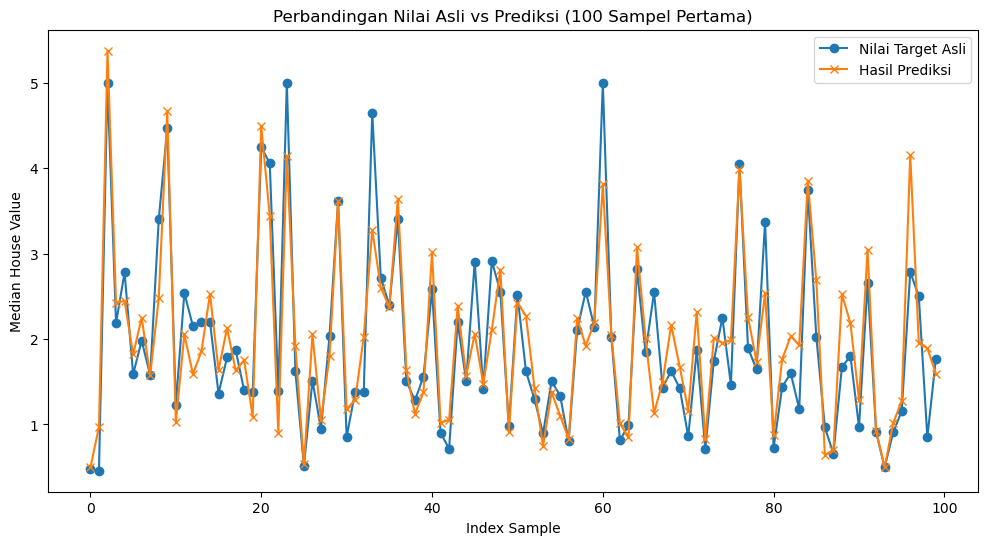

In [110]:
import pandas as pd
import tensorflow as tf
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Input
from tensorflow.keras.callbacks import EarlyStopping
import matplotlib.pyplot as plt
import numpy as np
import random

# Set seed
random.seed(42)
np.random.seed(42)
tf.random.set_seed(42)

from sklearn.datasets import fetch_california_housing
data = fetch_california_housing()
df = pd.DataFrame(data.data, columns=data.feature_names)
df['target'] = data.target

# Split data
train_df, test_df = train_test_split(df, test_size=0.2, random_state=42)
scaler = StandardScaler()
X_train = scaler.fit_transform(train_df[data.feature_names])
X_test = scaler.transform(test_df[data.feature_names])
y_train = train_df['target'].values
y_test = test_df['target'].values

batch_size = 32
train_ds = tf.data.Dataset.from_tensor_slices((X_train, y_train)).shuffle(len(X_train)).batch(batch_size)
test_ds = tf.data.Dataset.from_tensor_slices((X_test, y_test)).batch(batch_size)

# Model: tambah hidden layer & neuron
model = Sequential([
    Input(shape=(X_train.shape[1],)),
    Dense(256, activation='relu'),
    Dense(128, activation='relu'),
    Dense(64, activation='relu'),
    Dense(32, activation='relu'),
    Dense(1)
])

model.compile(optimizer='adam', loss='mse', metrics=['mae'])

# Early stopping callback
early_stop = EarlyStopping(
    monitor='val_loss',
    patience=5,       # Stop jika tidak membaik selama 5 epoch
    restore_best_weights=True
)

# Training model, tambah validation_split
history = model.fit(
    X_train, y_train,
    validation_split=0.2,
    epochs=100,
    batch_size=32,
    callbacks=[early_stop],
    verbose=1
)

# Evaluasi di test set
loss, mae = model.evaluate(X_test, y_test)
print(f"Test MAE : {mae:.2f}")

# Plot grafik loss
plt.figure(figsize=(10,5))
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Training vs Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('MSE Loss')
plt.legend()
plt.show()

# Prediksi di test set
y_pred = model.predict(X_test).flatten()
N = 100
plt.figure(figsize=(12, 6))
plt.plot(y_test[:N], label='Nilai Target Asli', marker='o')
plt.plot(y_pred[:N], label='Hasil Prediksi', marker='x')
plt.title('Perbandingan Nilai Asli vs Prediksi (100 Sampel Pertama)')
plt.xlabel('Index Sample')
plt.ylabel('Median House Value')
plt.legend()
plt.show()

Sequential API multi regression

In [111]:
from sklearn.datasets import load_linnerud

data = load_linnerud()
X = pd.DataFrame(data.data, columns=data.feature_names)
Y = pd.DataFrame(data.target, columns=data.target_names)

df_all = pd.concat([X, Y], axis=1)
df_all

,Chins,Situps,Jumps,Weight,Waist,Pulse
0,5.0,162.0,60.0,191.0,36.0,50.0
1,2.0,110.0,60.0,189.0,37.0,52.0
2,12.0,101.0,101.0,193.0,38.0,58.0
3,12.0,105.0,37.0,162.0,35.0,62.0
4,13.0,155.0,58.0,189.0,35.0,46.0
5,4.0,101.0,42.0,182.0,36.0,56.0
6,8.0,101.0,38.0,211.0,38.0,56.0
7,6.0,125.0,40.0,167.0,34.0,60.0
8,15.0,200.0,40.0,176.0,31.0,74.0
9,17.0,251.0,250.0,154.0,33.0,56.0


In [112]:
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.2, random_state=42)

scaler_X = StandardScaler()
X_train_scaled = scaler_X.fit_transform(X_train)
X_test_scaled = scaler_X.transform(X_test)

scaler_Y = StandardScaler()
Y_train_scaled = scaler_Y.fit_transform(Y_train)
Y_test_scaled = scaler_Y.transform(Y_test)

batch_size = 8
train_ds = tf.data.Dataset.from_tensor_slices((X_train_scaled, Y_train_scaled)).shuffle(len(X_train)).batch(batch_size)
test_ds = tf.data.Dataset.from_tensor_slices((X_test_scaled, Y_test_scaled)).batch(batch_size)

model = Sequential([
    Input(shape=(X_train.shape[1],)),
    Dense(32, activation='relu'),
    Dense(16, activation='relu'),
    Dense(Y_train.shape[1])  
])

model.compile(optimizer='adam', loss='mse', metrics=['mae'])

model.fit(train_ds, epochs=50)

loss, mae = model.evaluate(test_ds)

Epoch 1/50


2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.9487 - mae: 0.7570  
Epoch 2/50
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.9776 - mae: 0.7888
Epoch 3/50
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.9485 - mae: 0.7663
Epoch 4/50
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 1.0474 - mae: 0.7907
Epoch 5/50
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 1.0091 - mae: 0.8115
Epoch 6/50
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.9619 - mae: 0.7869
Epoch 7/50
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.9589 - mae: 0.7736
Epoch 8/50
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 1.1246 - mae: 0.8266
Epoch 9/50
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - loss: 1.1205 - mae: 0.8230
Epoch 10/50
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 1.0488 - mae: 0.7880
Epoch 11/50
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 1.0607 - mae: 0.7740
Epoch 12/50
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.8850 - mae: 0.7231
Epoch 13/50
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 1.0107 - mae: 0.7682
Epo

In [113]:
Y_pred_scaled = model.predict(test_ds)
Y_pred = scaler_Y.inverse_transform(Y_pred_scaled)
print("Prediksi 5 data pertama (satuan asli):\n", Y_pred[:5])
print("Target asli 5 data pertama:\n", Y_test.values[:5])
print(f"MAE : {mae:.2f}")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 52ms/step
Prediksi 5 data pertama (satuan asli):
 [[168.4155    35.591347  57.187717]
 [169.14366   34.208244  59.58424 ]
 [168.94482   34.381977  56.27191 ]
 [182.40482   37.047405  56.45624 ]]
Target asli 5 data pertama:
 [[191.  36.  50.]
 [157.  32.  52.]
 [202.  37.  62.]
 [189.  37.  52.]]
MAE : 0.66


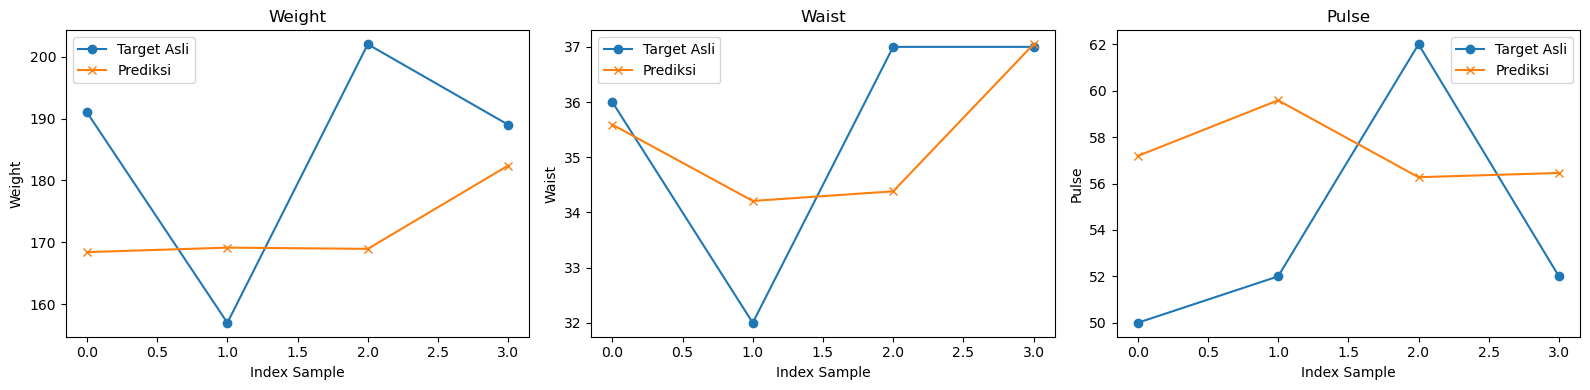

In [114]:
N = min(100, Y_pred.shape[0])

target_names = Y.columns

plt.figure(figsize=(16, 4))
for i, col in enumerate(target_names):
    plt.subplot(1, 3, i+1)
    plt.plot(Y_test.values[:N, i], label='Target Asli', marker='o')
    plt.plot(Y_pred[:N, i], label='Prediksi', marker='x')
    plt.title(col)
    plt.xlabel('Index Sample')
    plt.ylabel(col)
    plt.legend()
plt.tight_layout()
plt.show()

In [115]:
import pandas as pd

df = pd.read_csv('StudentPerformanceFactors.csv')
df.head()


,Hours_Studied,Attendance,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Sleep_Hours,Previous_Scores,Motivation_Level,Internet_Access,Tutoring_Sessions,Family_Income,Teacher_Quality,School_Type,Peer_Influence,Physical_Activity,Learning_Disabilities,Parental_Education_Level,Distance_from_Home,Gender,Exam_Score
0,23,84,Low,High,No,7,73,Low,Yes,0,Low,Medium,Public,Positive,3,No,High School,Near,Male,67
1,19,64,Low,Medium,No,8,59,Low,Yes,2,Medium,Medium,Public,Negative,4,No,College,Moderate,Female,61
2,24,98,Medium,Medium,Yes,7,91,Medium,Yes,2,Medium,Medium,Public,Neutral,4,No,Postgraduate,Near,Male,74
3,29,89,Low,Medium,Yes,8,98,Medium,Yes,1,Medium,Medium,Public,Negative,4,No,High School,Moderate,Male,71
4,19,92,Medium,Medium,Yes,6,65,Medium,Yes,3,Medium,High,Public,Neutral,4,No,College,Near,Female,70


In [116]:
Y = df[['Exam_Score', 'Previous_Scores']]  
X = df.drop(columns=['Exam_Score', 'Previous_Scores'])

In [117]:
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer

numeric_features = X.select_dtypes(include='number').columns.tolist()
categorical_features = X.select_dtypes(exclude='number').columns.tolist()

preprocessor = ColumnTransformer([
    ('num', StandardScaler(), numeric_features),
    ('cat', OneHotEncoder(drop='first'), categorical_features)
])

X_processed = preprocessor.fit_transform(X)
scaler_Y = StandardScaler()
Y_scaled = scaler_Y.fit_transform(Y)

In [118]:
X_train, X_test, Y_train, Y_test = train_test_split(X_processed, Y_scaled, test_size=0.2, random_state=42)

In [119]:
model = Sequential([
    Input(shape=(X_train.shape[1],)),
    Dense(64, activation='relu'),
    Dense(32, activation='relu'),
    Dense(Y_train.shape[1])  
])
model.compile(optimizer='adam', loss='mse', metrics=['mae'])

In [120]:
history = model.fit(X_train, Y_train, epochs=50, validation_split=0.2)

Epoch 1/50
133/133 ━━━━━━━━━━━━━━━━━━━━ 0s 888us/step - loss: 0.8039 - mae: 0.6871 - val_loss: 0.8169 - val_mae: 0.5958
Epoch 2/50
133/133 ━━━━━━━━━━━━━━━━━━━━ 0s 503us/step - loss: 0.6384 - mae: 0.5611 - val_loss: 0.8013 - val_mae: 0.5788
Epoch 3/50
133/133 ━━━━━━━━━━━━━━━━━━━━ 0s 498us/step - loss: 0.6234 - mae: 0.5468 - val_loss: 0.7996 - val_mae: 0.5752
Epoch 4/50
133/133 ━━━━━━━━━━━━━━━━━━━━ 0s 486us/step - loss: 0.6163 - mae: 0.5417 - val_loss: 0.7991 - val_mae: 0.5749
Epoch 5/50
133/133 ━━━━━━━━━━━━━━━━━━━━ 0s 486us/step - loss: 0.6116 - mae: 0.5393 - val_loss: 0.8006 - val_mae: 0.5738
Epoch 6/50
133/133 ━━━━━━━━━━━━━━━━━━━━ 0s 494us/step - loss: 0.6069 - mae: 0.5372 - val_loss: 0.8021 - val_mae: 0.5756
Epoch 7/50
133/133 ━━━━━━━━━━━━━━━━━━━━ 0s 486us/step - loss: 0.6030 - mae: 0.5355 - val_loss: 0.8032 - val_mae: 0.5757
Epoch 8/50
133/133 ━━━━━━━━━━━━━━━━━━━━ 0s 491us/step - loss: 0.5987 - mae: 0.5335 - val_loss: 0.8047 - val_mae: 0.5768
Epoch 9/50
133/133 ━━━━━━━━━━━━━━━━━━━━ 

In [121]:
loss, mae = model.evaluate(X_test, Y_test)
print(f"Test MAE (standar deviasi): {mae:.2f}")

42/42 ━━━━━━━━━━━━━━━━━━━━ 0s 448us/step - loss: 0.8199 - mae: 0.6147
Test MAE (standar deviasi): 0.61


In [122]:
Y_pred_scaled = model.predict(X_test)
Y_pred = scaler_Y.inverse_transform(Y_pred_scaled)
Y_test_unscaled = scaler_Y.inverse_transform(Y_test)

print("Prediksi 5 data pertama (satuan asli):\n", Y_pred[:5])
print("Target asli 5 data pertama:\n", Y_test_unscaled[:5])
print(f"MAE : {mae:.2f}")

42/42 ━━━━━━━━━━━━━━━━━━━━ 0s 583us/step
Prediksi 5 data pertama (satuan asli):
 [[63.844803 74.777695]
 [63.4725   70.63716 ]
 [72.98143  80.39842 ]
 [63.89993  67.95752 ]
 [64.92114  67.89067 ]]
Target asli 5 data pertama:
 [[65. 87.]
 [65. 98.]
 [71. 53.]
 [64. 81.]
 [66. 95.]]
MAE : 0.61


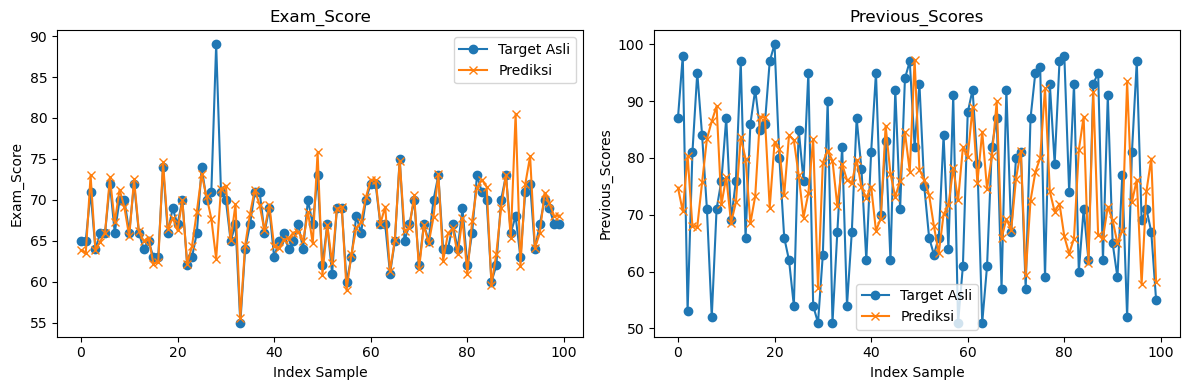

In [123]:
import matplotlib.pyplot as plt

target_names = Y.columns
N = min(100, Y_pred.shape[0])

plt.figure(figsize=(12, 4))
for i, col in enumerate(target_names):
    plt.subplot(1, len(target_names), i+1)
    plt.plot(Y_test_unscaled[:N, i], label='Target Asli', marker='o')
    plt.plot(Y_pred[:N, i], label='Prediksi', marker='x')
    plt.title(col)
    plt.xlabel('Index Sample')
    plt.ylabel(col)
    plt.legend()
plt.tight_layout()
plt.show()

Sequential API ( binary classification )

In [124]:
from sklearn.datasets import load_breast_cancer

data = load_breast_cancer()
df = pd.DataFrame(data.data, columns=data.feature_names)
df['label'] = data.target
df.columns

Index(['mean radius', 'mean texture', 'mean perimeter', 'mean area',
       'mean smoothness', 'mean compactness', 'mean concavity',
       'mean concave points', 'mean symmetry', 'mean fractal dimension',
       'radius error', 'texture error', 'perimeter error', 'area error',
       'smoothness error', 'compactness error', 'concavity error',
       'concave points error', 'symmetry error', 'fractal dimension error',
       'worst radius', 'worst texture', 'worst perimeter', 'worst area',
       'worst smoothness', 'worst compactness', 'worst concavity',
       'worst concave points', 'worst symmetry', 'worst fractal dimension',
       'label'],
      dtype='object')

In [125]:
train_df, test_df = train_test_split(df, test_size=0.2, random_state=42)

scaler = StandardScaler()
X_train = scaler.fit_transform(train_df[data.feature_names])
X_test = scaler.transform(test_df[data.feature_names])
y_train = train_df['label'].values
y_test = test_df['label'].values

batch_size = 16
train_ds = tf.data.Dataset.from_tensor_slices((X_train, y_train)).shuffle(len(X_train)).batch(batch_size)
test_ds = tf.data.Dataset.from_tensor_slices((X_test, y_test)).batch(batch_size)

model = Sequential([
    Input(shape=(X_train.shape[1],)),
    Dense(32, activation='relu'),
    Dense(16, activation='relu'),
    Dense(1, activation='sigmoid')
])

model.compile(optimizer='adam', 
              loss='binary_crossentropy', 
              metrics=['accuracy'])

model.fit(train_ds, epochs=10)

loss, acc = model.evaluate(test_ds)

Epoch 1/10
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 398us/step - accuracy: 0.6463 - loss: 0.6692
Epoch 2/10
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 392us/step - accuracy: 0.9101 - loss: 0.4072
Epoch 3/10
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 328us/step - accuracy: 0.9388 - loss: 0.2491
Epoch 4/10
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 317us/step - accuracy: 0.9440 - loss: 0.1602
Epoch 5/10
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 337us/step - accuracy: 0.9647 - loss: 0.1470
Epoch 6/10
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 312us/step - accuracy: 0.9796 - loss: 0.1071
Epoch 7/10
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 318us/step - accuracy: 0.9813 - loss: 0.0817
Epoch 8/10
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 310us/step - accuracy: 0.9804 - loss: 0.0779
Epoch 9/10
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 307us/step - accuracy: 0.9813 - loss: 0.0769
Epoch 10/10
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 308us/step - accuracy: 0.9764 - loss: 0.0842
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 701us/step - accuracy: 0.9815 - loss: 0.0733


In [126]:
y_pred_prob = model.predict(test_ds)
y_pred_class = (y_pred_prob > 0.5).astype(int)
print("Contoh prediksi kelas batch pertama:", y_pred_class[:5].ravel())
print("Label asli batch pertama:", y_test[:5])
print(f"Test Accuracy: {acc:.2f}")

8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step 
Contoh prediksi kelas batch pertama: [1 0 0 1 1]
Label asli batch pertama: [1 0 0 1 1]
Test Accuracy: 0.98


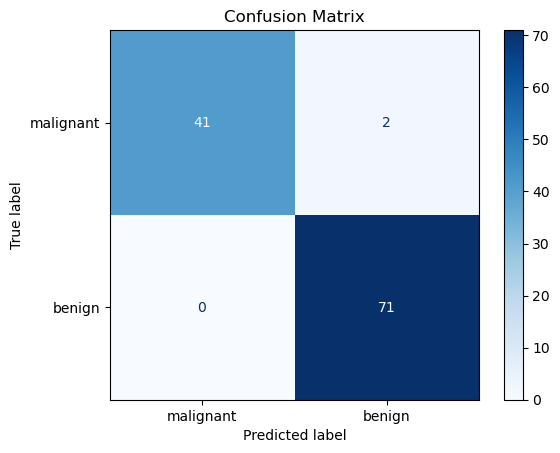

In [127]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

y_pred_class_flat = y_pred_class.flatten()

cm = confusion_matrix(y_test, y_pred_class_flat)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=data.target_names)
disp.plot(cmap=plt.cm.Blues)
plt.title("Confusion Matrix")
plt.show()

In [152]:
df = pd.read_csv('breast_cancer_survival.csv')
df.head()

,Age,Gender,Protein1,Protein2,Protein3,Protein4,Tumour_Stage,Histology,ER status,PR status,HER2 status,Surgery_type,Date_of_Surgery,Date_of_Last_Visit,Patient_Status
0,42,FEMALE,0.95256,2.15000,0.007972,-0.048340,II,Infiltrating Ductal Carcinoma,Positive,Positive,Negative,Other,20-May-18,26-Aug-18,Alive
1,54,FEMALE,0.00000,1.38020,-0.498030,-0.507320,II,Infiltrating Ductal Carcinoma,Positive,Positive,Negative,Other,26-Apr-18,25-Jan-19,Dead
2,63,FEMALE,-0.52303,1.76400,-0.370190,0.010815,II,Infiltrating Ductal Carcinoma,Positive,Positive,Negative,Lumpectomy,24-Aug-18,08-Apr-20,Alive
3,78,FEMALE,-0.87618,0.12943,-0.370380,0.132190,I,Infiltrating Ductal Carcinoma,Positive,Positive,Negative,Other,16-Nov-18,28-Jul-20,Alive
4,42,FEMALE,0.22611,1.74910,-0.543970,-0.390210,II,Infiltrating Ductal Carcinoma,Positive,Positive,Positive,Lumpectomy,12-Dec-18,05-Jan-19,Alive


In [153]:
df['Patient_Status'] = (df['Patient_Status'] == 'Alive').astype(int)

df = df.drop(['Date_of_Surgery', 'Date_of_Last_Visit'], axis=1)

categorical_cols = ['Gender', 'Tumour_Stage', 'Histology', 
                    'ER status', 'PR status', 'HER2 status', 'Surgery_type']
df = pd.get_dummies(df, columns=categorical_cols)

print("Distribusi label:")
print(df['Patient_Status'].value_counts())


Distribusi label:
Patient_Status
1    255
0     79
Name: count, dtype: int64


In [154]:
from imblearn.over_sampling import RandomOverSampler

X = df.drop(columns=['Patient_Status'])
y = df['Patient_Status'].values

ros = RandomOverSampler(random_state=42)
X_res, y_res = ros.fit_resample(X, y)

print("Distribusi label setelah oversampling:")
print(pd.Series(y_res).value_counts())

Distribusi label setelah oversampling:
1    255
0    255
Name: count, dtype: int64


In [155]:
X_train, X_test, y_train, y_test = train_test_split(
    X_res, y_res, test_size=0.2, random_state=42, stratify=y_res)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

batch_size = 16
train_ds = tf.data.Dataset.from_tensor_slices((X_train, y_train)).shuffle(len(X_train)).batch(batch_size)
test_ds = tf.data.Dataset.from_tensor_slices((X_test, y_test)).batch(batch_size)

In [156]:
model = Sequential([
    Input(shape=(X_train.shape[1],)),
    Dense(32, activation='relu'),
    Dense(16, activation='relu'),
    Dense(1, activation='sigmoid')
])

model.compile(optimizer='adam', 
              loss='binary_crossentropy', 
              metrics=['accuracy'])

model.fit(train_ds, epochs=20, verbose=1)

Epoch 1/20
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 431us/step - accuracy: 0.4644 - loss: 0.7132
Epoch 2/20
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 342us/step - accuracy: 0.5727 - loss: 0.6941
Epoch 3/20
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 320us/step - accuracy: 0.5686 - loss: 0.6806
Epoch 4/20
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 346us/step - accuracy: 0.6839 - loss: 0.6496
Epoch 5/20
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 316us/step - accuracy: 0.6943 - loss: 0.6385
Epoch 6/20
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 315us/step - accuracy: 0.7280 - loss: 0.6179
Epoch 7/20
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 318us/step - accuracy: 0.7202 - loss: 0.6039
Epoch 8/20
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 314us/step - accuracy: 0.7180 - loss: 0.5978
Epoch 9/20
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 321us/step - accuracy: 0.7242 - loss: 0.5919
Epoch 10/20
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 312us/step - accuracy: 0.7335 - loss: 0.5804
Epoch 11/20
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 320us/step - accuracy: 0.7648 - loss: 0.5535
Epoch 12/20
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 320us/step

7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 600us/step - accuracy: 0.6649 - loss: 0.5953
Test Accuracy: 0.72
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step 


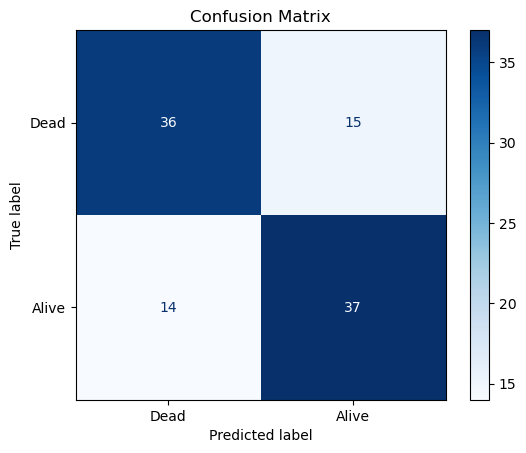

Classification Report:

              precision    recall  f1-score   support

        Dead       0.72      0.71      0.71        51
       Alive       0.71      0.73      0.72        51

    accuracy                           0.72       102
   macro avg       0.72      0.72      0.72       102
weighted avg       0.72      0.72      0.72       102



In [157]:
loss, acc = model.evaluate(test_ds)
print(f"Test Accuracy: {acc:.2f}")

y_pred_prob = model.predict(X_test)
y_pred_class = (y_pred_prob > 0.5).astype(int)

cm = confusion_matrix(y_test, y_pred_class)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Dead", "Alive"])
disp.plot(cmap='Blues')
plt.title("Confusion Matrix")
plt.show()